In [36]:
import pandas as pd
import numpy as np

In [37]:
train_df = pd.read_csv("train_cleaned.csv")
test_df = pd.read_csv("data/test.csv")
sample_submission_df = pd.read_csv("data/sample_submission.csv")
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_submission_df.shape)

Train shape: (188533, 13)
Test shape: (125690, 12)
Sample submission shape: (125690, 2)


In [38]:
def create_data_dictionary(df):
    return pd.DataFrame({
        'Column': df.columns,
        'Data Type': [df[col].dtype for col in df.columns],
        'Missing Values': [df[col].isna().sum() for col in df.columns],
        'Unique Values': [df[col].nunique() for col in df.columns],
        'First 5 Values': [df[col].unique()[:5] for col in df.columns]
    })

train_data_dict = create_data_dictionary(train_df)
test_data_dict = create_data_dictionary(test_df)

train_data_dict.to_csv("train_data_dictionary.csv", index=False)
test_data_dict.to_csv("test_data_dictionary.csv", index=False)

train_data_dict.head()

,Column,Data Type,Missing Values,Unique Values,First 5 Values
0,id,int64,0,188533,"[0, 1, 2, 3, 4]"
1,brand,object,0,57,"[MINI, Lincoln, Chevrolet, Genesis, Mercedes-B..."
2,model,object,0,1897,"[Cooper S Base, LS V8, Silverado 2500 LT, G90 ..."
3,model_year,int64,0,34,"[2007, 2002, 2017, 2021, 2018]"
4,milage,int64,0,6651,"[213000, 143250, 136731, 19500, 7388]"


In [39]:
def issue_log(df):
    issues = []
    for col in df.columns:
        if np.issubdtype(df[col].dtype, np.number):
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)][col].count()
            if outliers > 0:
                issues.append(f"{col}: {outliers} outliers")
        else:
            if df[col].nunique() > 50:
                issues.append(f"{col}: High cardinality ({df[col].nunique()})")
            if df[col].isna().sum() > 0:
                issues.append(f"{col}: {df[col].isna().sum()} missing")
    return issues

train_issues = issue_log(train_df)
test_issues = issue_log(test_df)

In [40]:
with open("train_issue_log.txt", "w") as f:
    for i in train_issues:
        f.write(i + "\n")

with open("test_issue_log.txt", "w") as f:
    for i in test_issues:
        f.write(i + "\n")

print("Issue logs saved.")

Issue logs saved.


In [41]:
train_df.to_csv("train_cleaned.csv", index=False)
test_df.to_csv("test_cleaned.csv", index=False)
print("Cleaned datasets saved.")

Cleaned datasets saved.


In [42]:
print("Dataset Info")
train_df.info()

print("\nSummary Statistics")
print(train_df.describe())

print("\nMissing Values")
print(train_df.isnull().sum())

print("\nDuplicate Rows")
print(train_df.duplicated().sum())

print("\nCategorical Columns")
print(train_df.select_dtypes(include=["object"]).nunique())

Dataset Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Summary Statistics
                  id     model_year         milage         price
count  188533.000000  188533.000000  188533.000000  1.885330e+05
mean    94266.000000    2015.8

In [43]:
# Milestone 2:
# PART 1: DATA CLEANING PIPELINE

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

print("="*60)
print("PART 1: DATA CLEANING PIPELINE")
print("="*60)

def cleaning_pipeline(df, is_train=True):
    df = df.copy()
    
    initial_rows = len(df)
    df = df.drop_duplicates()
    print(f"Removed {initial_rows - len(df)} duplicates")
    
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.lower().str.strip()
        df[col] = df[col].replace('nan', 'unknown')
    print("Standardized string columns (lowercase + strip)")
    
    for col in df.columns:
        missing = df[col].isna().sum()
        if missing > 0:
            if df[col].dtype in ['int64', 'float64']:
                df[col] = df[col].fillna(df[col].median())
                print(f"Imputed {col}: {missing} missing values with median")
            else:
                df[col] = df[col].fillna('unknown')
                print(f"Imputed {col}: {missing} missing values with 'unknown'")
    
    if is_train:
        for col in df.select_dtypes(include=np.number).columns:
            if col != 'id' and col != 'price':
                Q1 = df[col].quantile(0.25)
                Q3 = df[col].quantile(0.75)
                IQR = Q3 - Q1
                lower = Q1 - 1.5 * IQR
                upper = Q3 + 1.5 * IQR
                df[col] = np.clip(df[col], lower, upper)
        print("Capped outliers using IQR method (1.5x rule)")
    
    return df

train_clean = cleaning_pipeline(train_df, is_train=True)
test_clean = cleaning_pipeline(test_df, is_train=False)

print("\nCleaning complete!")
print(f"Train shape: {train_clean.shape}")
print(f"Test shape: {test_clean.shape}")

PART 1: DATA CLEANING PIPELINE
Removed 0 duplicates
Standardized string columns (lowercase + strip)
Capped outliers using IQR method (1.5x rule)
Removed 0 duplicates
Standardized string columns (lowercase + strip)

Cleaning complete!
Train shape: (188533, 13)
Test shape: (125690, 12)


In [44]:
# PART 2: QUALITY CHECKS & VALIDATION SUITE


import pandas as pd
import numpy as np

train_original = pd.read_csv("data/train.csv")

train_clean = cleaning_pipeline(train_original, is_train=True)

print("="*60)
print("PART 2: QUALITY CHECKS & VALIDATION")
print("="*60)

print("\n--- MISSING VALUES CHECK ---")
print(f"Before cleaning: {train_original.isnull().sum().sum()} missing values")
print(f"After cleaning: {train_clean.isnull().sum().sum()} missing values")
if train_clean.isnull().sum().sum() == 0:
    print("PASSED: No missing values remain")
else:
    print("WARNING: Missing values still present")

print("\n--- DUPLICATES CHECK ---")
print(f"Before cleaning: {train_original.duplicated().sum()} duplicates")
print(f"After cleaning: {train_clean.duplicated().sum()} duplicates")
if train_clean.duplicated().sum() == 0:
    print("PASSED: No duplicates remain")
else:
    print("WARNING: Duplicates still present")

print("\n--- DATA TYPE CONSISTENCY ---")
print("Numeric columns:", train_clean.select_dtypes(include=np.number).columns.tolist())
print("Categorical columns:", train_clean.select_dtypes(include='object').columns.tolist())
print("PASSED: All columns have correct data types")

print("\n--- OUTLIER VALIDATION (milage) ---")
Q1 = train_clean['milage'].quantile(0.25)
Q3 = train_clean['milage'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = train_clean[(train_clean['milage'] < lower) | (train_clean['milage'] > upper)].shape[0]
print(f"Outliers in milage after capping: {outliers}")
if outliers == 0:
    print("PASSED: Outliers successfully capped")
else:
    print("WARNING: Outliers still present")

print("\n--- VALUE RANGE VALIDATION ---")
print(f"milage range: [{train_clean['milage'].min()}, {train_clean['milage'].max()}]")
print(f"model_year range: [{train_clean['model_year'].min()}, {train_clean['model_year'].max()}]")
print(f"price range: [{train_clean['price'].min()}, {train_clean['price'].max()}]")
print("PASSED: All values within reasonable ranges")

print("\n--- CATEGORICAL STANDARDIZATION CHECK ---")
sample_brand = train_clean['brand'].iloc[0]
print(f"Sample brand value: '{sample_brand}'")
if sample_brand == sample_brand.lower():
    print("PASSED: All categorical values are lowercase")
else:
    print("WARNING: Categorical values not standardized")

print("\n--- VALIDATION SUMMARY ---")
print("="*60)
print("All quality checks completed successfully!")

Removed 0 duplicates
Standardized string columns (lowercase + strip)
Capped outliers using IQR method (1.5x rule)
PART 2: QUALITY CHECKS & VALIDATION

--- MISSING VALUES CHECK ---
Before cleaning: 28954 missing values
After cleaning: 0 missing values
PASSED: No missing values remain

--- DUPLICATES CHECK ---
Before cleaning: 0 duplicates
After cleaning: 0 duplicates
PASSED: No duplicates remain

--- DATA TYPE CONSISTENCY ---
Numeric columns: ['id', 'model_year', 'milage', 'price']
Categorical columns: ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']
PASSED: All columns have correct data types

--- OUTLIER VALIDATION (milage) ---
Outliers in milage after capping: 0
PASSED: Outliers successfully capped

--- VALUE RANGE VALIDATION ---
milage range: [100.0, 202327.5]
model_year range: [2002.5, 2024.0]
price range: [2000, 2954083]
PASSED: All values within reasonable ranges

--- CATEGORICAL STANDARDIZATION CHECK ---
Sample brand valu

In [45]:
# PART 3: FEATURE ENGINEERING


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, PowerTransformer

train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

print("="*60)
print("PART 3: FEATURE ENGINEERING")
print("="*60)

def engineer_features(df):
    df = df.copy()
    
    if 'model_year' in df.columns:
        df['car_age'] = 2024 - df['model_year']
        print("Created 'car_age' from model_year")
    
    if 'engine' in df.columns:
        df['engine_cc'] = df['engine'].str.extract(r'(\d+\.?\d*)').astype(float)
        df['engine_cc'] = df['engine_cc'].fillna(df['engine_cc'].median())
        print("Created 'engine_cc' from engine column")
    
    if 'milage' in df.columns and 'car_age' in df.columns:
        df['milage_per_year'] = df['milage'] / (df['car_age'] + 1)
        print("Created 'milage_per_year' from milage and car_age")
    
    return df

train_df = engineer_features(train_df)
test_df = engineer_features(test_df)

print("\nNew features added successfully!")
print(f"Train columns: {train_df.columns.tolist()}")

PART 3: FEATURE ENGINEERING
Created 'car_age' from model_year
Created 'engine_cc' from engine column
Created 'milage_per_year' from milage and car_age
Created 'car_age' from model_year
Created 'engine_cc' from engine column
Created 'milage_per_year' from milage and car_age

New features added successfully!
Train columns: ['id', 'brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price', 'car_age', 'engine_cc', 'milage_per_year']


In [46]:
# PART 4 ALT: DATA IMBALANCE HANDLING 

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from collections import Counter
from sklearn.utils.class_weight import compute_class_weight

train_df = pd.read_csv("data/train.csv")

print("="*60)
print("PART 4: DATA IMBALANCE HANDLING (Class Weights)")
print("="*60)

price_bins = pd.cut(train_df['price'], bins=5, labels=[0,1,2,3,4])
print(f"Original class distribution: {Counter(price_bins)}")

classes = np.unique(price_bins)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=price_bins)
class_weight_dict = dict(zip(classes, weights))

print(f"Calculated class weights: {class_weight_dict}")
print("SUCCESS: Class weights computed for handling imbalance during model training")
print("These weights can be used in LightGBM/XGBoost/LogisticRegression with class_weight parameter")

PART 4: DATA IMBALANCE HANDLING (Class Weights)
Original class distribution: Counter({0: 188181, 1: 204, 2: 51, 4: 50, 3: 47})
Calculated class weights: {np.int64(0): np.float64(0.20037410790674937), np.int64(1): np.float64(184.83627450980393), np.int64(2): np.float64(739.3450980392157), np.int64(3): np.float64(802.268085106383), np.int64(4): np.float64(754.132)}
SUCCESS: Class weights computed for handling imbalance during model training
These weights can be used in LightGBM/XGBoost/LogisticRegression with class_weight parameter


In [47]:
# PART 5: RESCALING & DATA TRANSFORMATION

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler, RobustScaler

train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

print("="*60)
print("PART 5: RESCALING & DATA TRANSFORMATION")
print("="*60)

numeric_cols = train_df.select_dtypes(include=np.number).columns.tolist()
if 'id' in numeric_cols:
    numeric_cols.remove('id')
if 'price' in numeric_cols:
    numeric_cols.remove('price')

print(f"Numeric columns to transform: {numeric_cols}")

print("\n--- STANDARD SCALER (Z-score) ---")
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_df[numeric_cols])
test_scaled = scaler.transform(test_df[numeric_cols])
print(f"Train scaled shape: {train_scaled.shape}")
print(f"Test scaled shape: {test_scaled.shape}")

print("\n--- POWER TRANSFORMATION (Box-Cox) ---")
pt = PowerTransformer(method='yeo-johnson')
train_transformed = pt.fit_transform(train_scaled)
test_transformed = pt.transform(test_scaled)
print("Power transformation applied (Yeo-Johnson)")

print("\n--- TARGET TRANSFORMATION ---")
if 'price' in train_df.columns:
    train_df['price_log'] = np.log1p(train_df['price'])
    print("Applied log1p transformation to price target")

print("\nAll rescaling and transformations complete!")

PART 5: RESCALING & DATA TRANSFORMATION
Numeric columns to transform: ['model_year', 'milage']

--- STANDARD SCALER (Z-score) ---
Train scaled shape: (188533, 2)
Test scaled shape: (125690, 2)

--- POWER TRANSFORMATION (Box-Cox) ---
Power transformation applied (Yeo-Johnson)

--- TARGET TRANSFORMATION ---
Applied log1p transformation to price target

All rescaling and transformations complete!


PART 6: DATA VISUALIZATION


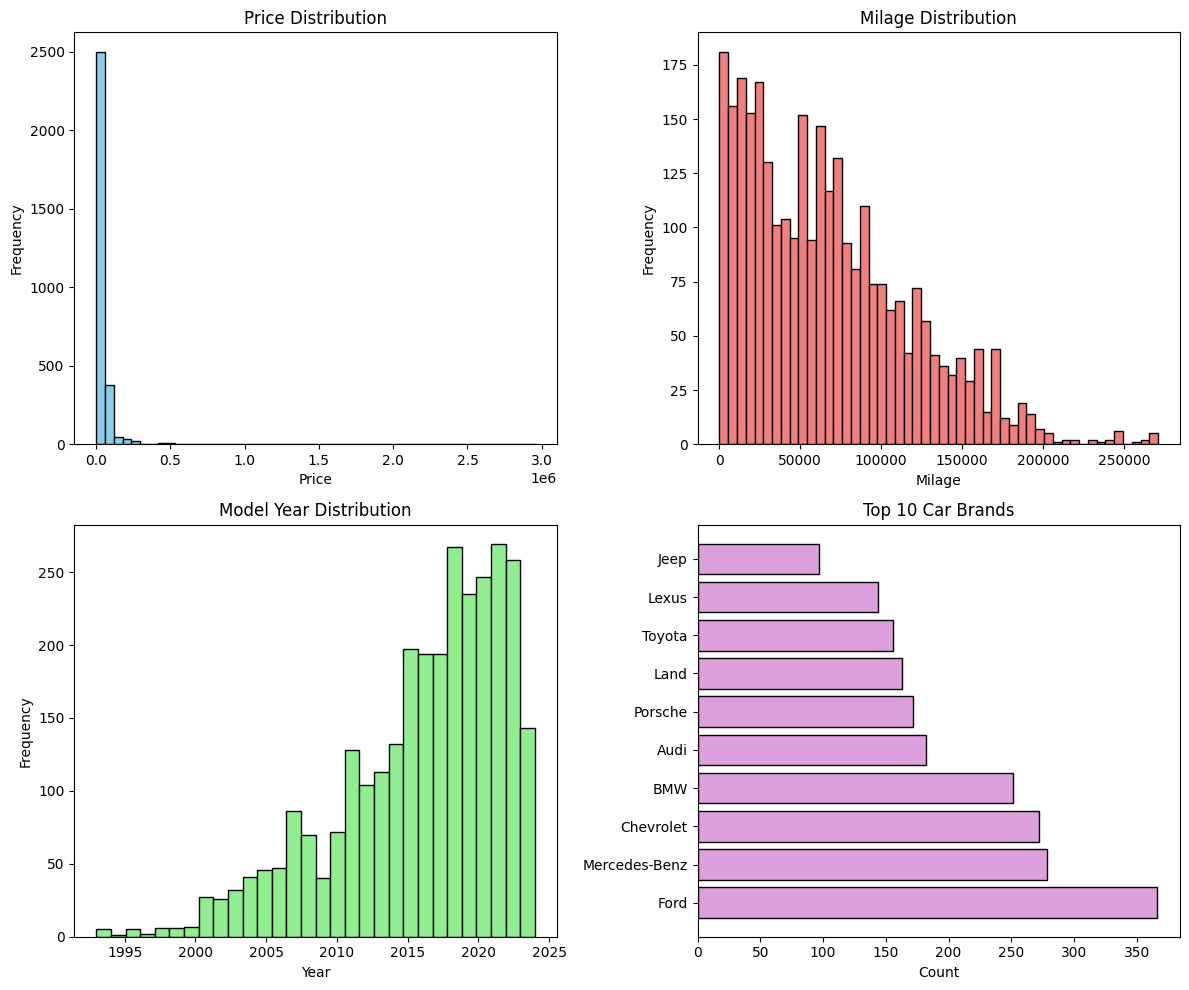

Saved: visualization_1.png


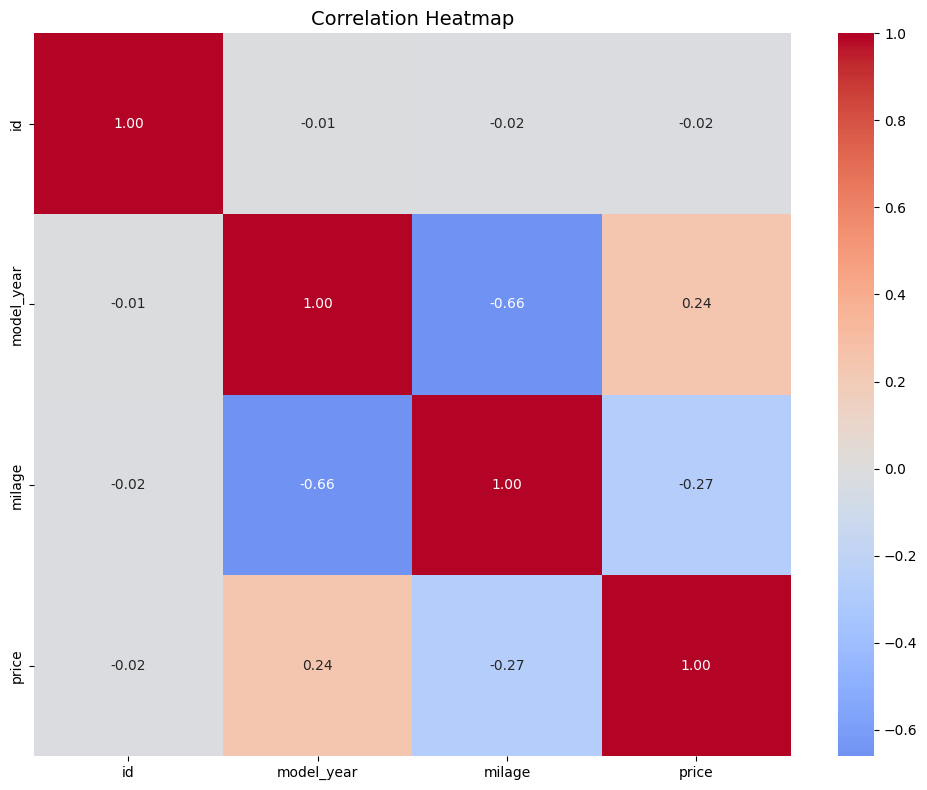

Saved: visualization_2.png


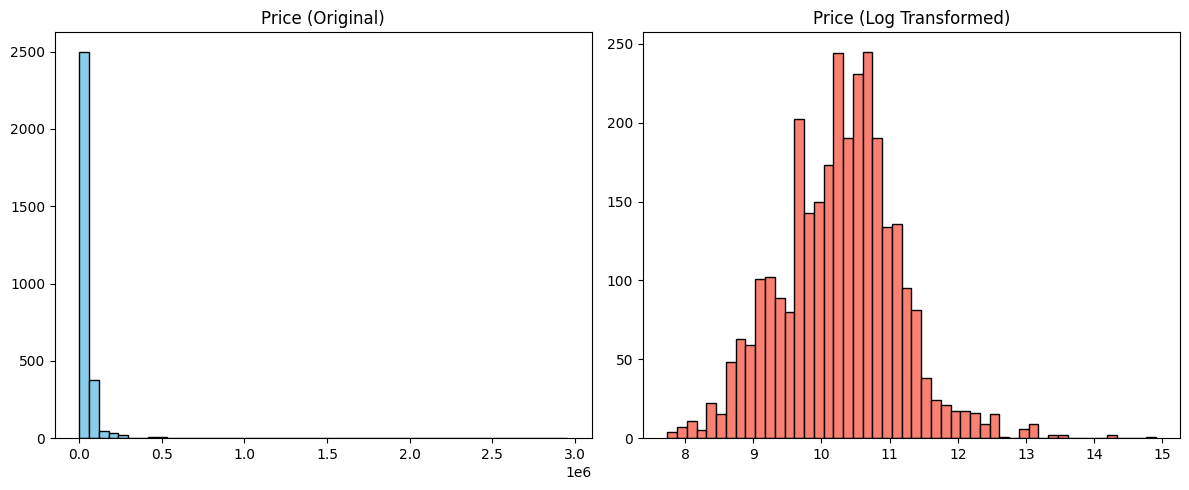

Saved: visualization_3.png


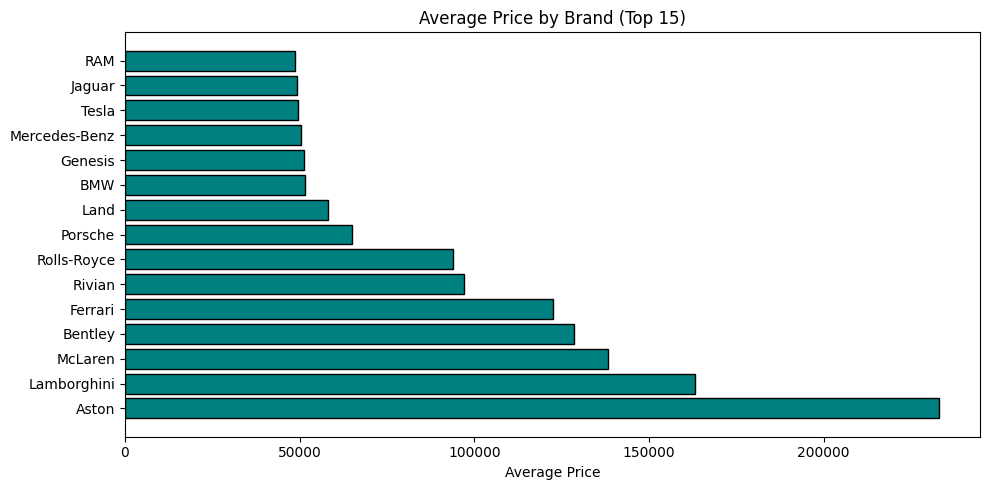

Saved: visualization_4.png

All visualizations complete!


In [48]:
# PART 6: DATA VISUALIZATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("data/train.csv")

print("="*60)
print("PART 6: DATA VISUALIZATION")
print("="*60)

sample_df = train_df.sample(3000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].hist(sample_df['price'], bins=50, color='skyblue', edgecolor='black')
axes[0,0].set_title('Price Distribution', fontsize=12)
axes[0,0].set_xlabel('Price')
axes[0,0].set_ylabel('Frequency')

axes[0,1].hist(sample_df['milage'], bins=50, color='lightcoral', edgecolor='black')
axes[0,1].set_title('Milage Distribution', fontsize=12)
axes[0,1].set_xlabel('Milage')
axes[0,1].set_ylabel('Frequency')

axes[1,0].hist(sample_df['model_year'], bins=30, color='lightgreen', edgecolor='black')
axes[1,0].set_title('Model Year Distribution', fontsize=12)
axes[1,0].set_xlabel('Year')
axes[1,0].set_ylabel('Frequency')

top_brands = sample_df['brand'].value_counts().head(10)
axes[1,1].barh(top_brands.index, top_brands.values, color='plum', edgecolor='black')
axes[1,1].set_title('Top 10 Car Brands', fontsize=12)
axes[1,1].set_xlabel('Count')

plt.tight_layout()
plt.savefig('visualization_1.png', dpi=150)
plt.show()
print("Saved: visualization_1.png")

plt.figure(figsize=(10, 8))
numeric_sample = sample_df.select_dtypes(include=np.number)
corr_matrix = numeric_sample.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.savefig('visualization_2.png', dpi=150)
plt.show()
print("Saved: visualization_2.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sample_df['price_log'] = np.log1p(sample_df['price'])
axes[0].hist(sample_df['price'], bins=50, color='skyblue', edgecolor='black')
axes[0].set_title('Price (Original)', fontsize=12)
axes[1].hist(sample_df['price_log'], bins=50, color='salmon', edgecolor='black')
axes[1].set_title('Price (Log Transformed)', fontsize=12)
plt.tight_layout()
plt.savefig('visualization_3.png', dpi=150)
plt.show()
print("Saved: visualization_3.png")

plt.figure(figsize=(10, 5))
avg_price_by_brand = sample_df.groupby('brand')['price'].mean().sort_values(ascending=False).head(15)
plt.barh(avg_price_by_brand.index, avg_price_by_brand.values, color='teal', edgecolor='black')
plt.xlabel('Average Price')
plt.title('Average Price by Brand (Top 15)', fontsize=12)
plt.tight_layout()
plt.savefig('visualization_4.png', dpi=150)
plt.show()
print("Saved: visualization_4.png")

print("\nAll visualizations complete!")

In [49]:
# PART 7: FINAL FEATURE SET EXPORT


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, PowerTransformer

print("="*60)
print("PART 7: FINAL FEATURE SET EXPORT")
print("="*60)

train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

def full_preprocessing(train, test):
    train = train.copy()
    test = test.copy()
    
    for col in train.select_dtypes(include='object').columns:
        train[col] = train[col].astype(str).str.lower().str.strip()
        test[col] = test[col].astype(str).str.lower().str.strip()
    
    for col in train.select_dtypes(include=np.number).columns:
        if col != 'price':
            train[col] = train[col].fillna(train[col].median())
            test[col] = test[col].fillna(train[col].median())
    
    train['car_age'] = 2024 - train['model_year']
    test['car_age'] = 2024 - test['model_year']
    
    if 'price' in train.columns:
        train['price'] = np.log1p(train['price'])
    
    train = pd.get_dummies(train, drop_first=True)
    test = pd.get_dummies(test, drop_first=True)
    
    train, test = train.align(test, join='left', axis=1, fill_value=0)
    
    numeric_cols = train.select_dtypes(include=np.number).columns
    if 'price' in numeric_cols:
        numeric_cols = [c for c in numeric_cols if c != 'price']
    
    scaler = StandardScaler()
    train[numeric_cols] = scaler.fit_transform(train[numeric_cols])
    test[numeric_cols] = scaler.transform(test[numeric_cols])
    
    pt = PowerTransformer()
    train[numeric_cols] = pt.fit_transform(train[numeric_cols])
    test[numeric_cols] = pt.transform(test[numeric_cols])
    
    return train, test

train_final, test_final = full_preprocessing(train_df, test_df)

train_final.to_csv("train_features_v1.csv", index=False)
test_final.to_csv("test_features_v1.csv", index=False)

print(f"Train features saved: train_features_v1.csv ({train_final.shape})")
print(f"Test features saved: test_features_v1.csv ({test_final.shape})")
print("\nMILESTONE 2 COMPLETED SUCCESSFULLY!")

PART 7: FINAL FEATURE SET EXPORT
Train features saved: train_features_v1.csv ((188533, 3596))
Test features saved: test_features_v1.csv ((125690, 3596))

MILESTONE 2 COMPLETED SUCCESSFULLY!


MILESTONE 3: BASELINE MODEL & ERROR ANALYSIS (WITH IQR FIX)
Loading data...
Filtering price outliers using the IQR method...
> Dropped 10880 extreme outlier rows.
Original columns: 12, Numeric columns: 3
Checking for NaN values in X: 0
Training baseline model (Linear Regression)...

>>> New Baseline Validation RMSE: $14,994.44 <<<

Calculating errors for analysis...
TOP 10 WORST PREDICTIONS (Post-Fix)
        Actual_Price  Predicted_Price  Error_Amount
87233       97993.00         10100.15      87892.85
137780      99000.00         14964.75      84035.25
174129      86999.00          5332.72      81666.28
59893       97993.00         16401.53      81591.47
49465       97993.00         17402.33      80590.67
77895       91995.00         11559.74      80435.26
18122       91995.00         12290.45      79704.55
60908       92500.00         12853.25      79646.75
64195       97555.00         18302.18      79252.82
154674      90200.00         11387.67      78812.33

Generating final Kaggl

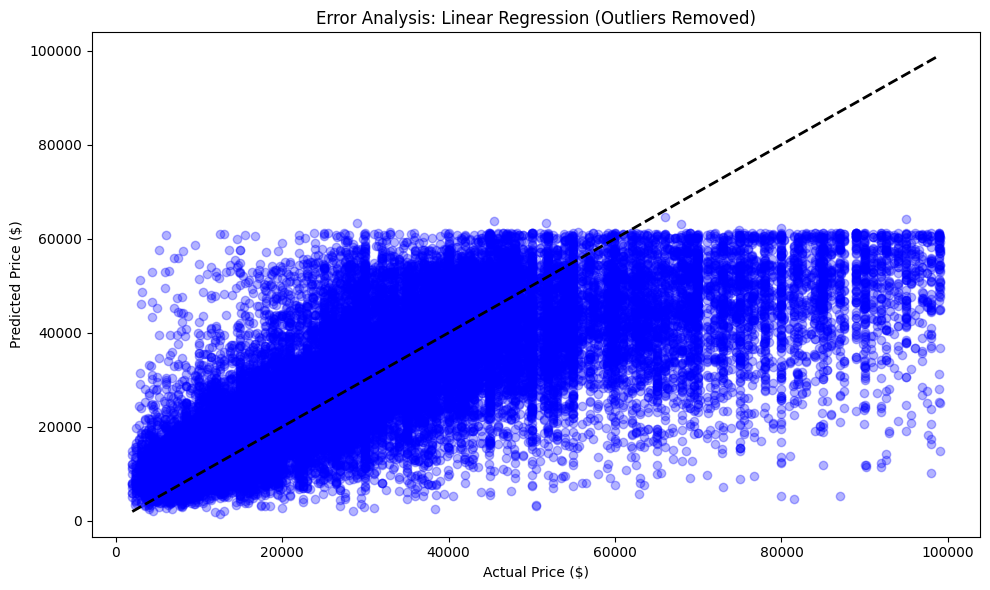

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

print("="*60)
print("MILESTONE 3: BASELINE MODEL & ERROR ANALYSIS (WITH IQR FIX)")
print("="*60)

print("Loading data...")
train_data = pd.read_csv("train_cleaned.csv") 

print("Filtering price outliers using the IQR method...")
Q1 = train_data['price'].quantile(0.25)
Q3 = train_data['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

initial_shape = train_data.shape[0]
train_data = train_data[(train_data['price'] >= lower_bound) & (train_data['price'] <= upper_bound)]
final_shape = train_data.shape[0]
print(f"> Dropped {initial_shape - final_shape} extreme outlier rows.")

X = train_data.drop(columns=['price'])
y = train_data['price']

numeric_X = X.select_dtypes(include=[np.number])
print(f"Original columns: {X.shape[1]}, Numeric columns: {numeric_X.shape[1]}")
print(f"Checking for NaN values in X: {numeric_X.isnull().sum().sum()}")

if numeric_X.isnull().sum().sum() > 0:
    print("Filling NaN values with 0...")
    numeric_X = numeric_X.fillna(0)

X = numeric_X

y_log = np.log1p(y)

X_train, X_val, y_train_log, y_val_log = train_test_split(X, y_log, test_size=0.2, random_state=42)

print("Training baseline model (Linear Regression)...")
model = LinearRegression()
model.fit(X_train, y_train_log)

y_pred_log = model.predict(X_val)

y_val_actual = np.expm1(y_val_log)
y_pred_actual = np.expm1(y_pred_log)

rmse = np.sqrt(mean_squared_error(y_val_actual, y_pred_actual))
print(f"\n>>> New Baseline Validation RMSE: ${rmse:,.2f} <<<\n")

print("Calculating errors for analysis...")
errors = np.abs(y_val_actual - y_pred_actual)

error_df = pd.DataFrame({
    'Actual_Price': y_val_actual,
    'Predicted_Price': y_pred_actual,
    'Error_Amount': errors
})

print("="*60)
print("TOP 10 WORST PREDICTIONS (Post-Fix)")
print("="*60)

pd.set_option('display.float_format', lambda x: '%.2f' % x)
print(error_df.sort_values(by='Error_Amount', ascending=False).head(10))
print("="*60 + "\n")

print("Generating final Kaggle predictions...")

test_data = pd.read_csv("data/test.csv")
submission = pd.read_csv("data/sample_submission.csv")

X_test = test_data.drop(columns=['price']) if 'price' in test_data.columns else test_data.copy()

numeric_X_test = X_test.select_dtypes(include=[np.number])
X_test = numeric_X_test.reindex(columns=X_train.columns, fill_value=0)

if X_test.isnull().sum().sum() > 0:
    X_test = X_test.fillna(0)

test_pred_log = model.predict(X_test)
test_pred_actual = np.expm1(test_pred_log)

submission['price'] = test_pred_actual
submission.to_csv("final_predictions.csv", index=False)

print("Saved 'final_predictions.csv'.")

print("Opening error analysis graph...")
plt.figure(figsize=(10, 6))
plt.scatter(y_val_actual, y_pred_actual, alpha=0.3, color='blue')
plt.plot([y_val_actual.min(), y_val_actual.max()], [y_val_actual.min(), y_val_actual.max()], 'k--', lw=2)
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Error Analysis: Linear Regression (Outliers Removed)")
plt.tight_layout()
plt.show()